TASK 6

In [2]:
import nltk
from nltk import CFG
from nltk.parse import RecursiveDescentParser
grammar6 = CFG.fromstring("""
S -> VP
VP -> V NP | V NP PP
NP -> DET N | N | N PP
PP -> P NP
V -> 'show'
DET -> 'the'
N -> 'students' | 'notice'
P -> 'with'
""")
parser6 = RecursiveDescentParser(grammar6)
sentence6 = "show the students with the notice".split()
trees6 = list(parser6.parse(sentence6))
print("Sentence:", " ".join(sentence6))
print("Number of parse trees:", len(trees6))
for i, tree in enumerate(trees6, 1):
    print("\nParse Tree", i)
    print(tree)
    tree.pretty_print()

Sentence: show the students with the notice
Number of parse trees: 1

Parse Tree 1
(S
  (VP
    (V show)
    (NP (DET the) (N students))
    (PP (P with) (NP (DET the) (N notice)))))
                S                        
                |                         
                VP                       
  ______________|___________              
 |        |                 PP           
 |        |             ____|___          
 |        NP           |        NP       
 |     ___|_____       |     ___|____     
 V   DET        N      P   DET       N   
 |    |         |      |    |        |    
show the     students with the     notice



task 9

In [3]:
import nltk
from nltk import Nonterminal, PCFG
from nltk.parse import ViterbiParser, InsideChartParser
grammar9 = PCFG.fromstring("""
S -> VP [1.0]
VP -> V NP [0.7] | VP PP [0.3]
NP -> N [0.6] | NP PP [0.4]
PP -> P N [1.0]
V -> 'show' [1.0]
N -> 'students' [0.6] | 'notice' [0.4]
P -> 'with' [1.0]
""")
sentence9 = "show students with notice".split()
viterbi = ViterbiParser(grammar9)
inside = InsideChartParser(grammar9)
trees = list(inside.parse(sentence9))
print("Sentence:", " ".join(sentence9))
print("\nPossible Parse Trees:")
for i, tree in enumerate(trees, 1):
    print("\nTree", i)
    print(tree)
    print("Probability:", tree.prob())
print("\nBest Viterbi Parse:")
best = list(viterbi.parse(sentence9))
for tree in best:
    print(tree)
    print("Best Probability:", tree.prob())
total_probability = sum(tree.prob() for tree in trees)
print("\nTotal Sentence Probability:", total_probability)

Sentence: show students with notice

Possible Parse Trees:

Tree 1
(S
  (VP
    (V show)
    (NP (NP (N students)) (PP (P with) (N notice))))) (p=0.04032)
Probability: 0.040319999999999995

Tree 2
(S
  (VP
    (VP (V show) (NP (N students)))
    (PP (P with) (N notice)))) (p=0.03024)
Probability: 0.030240000000000003

Best Viterbi Parse:
(S
  (VP
    (V show)
    (NP (NP (N students)) (PP (P with) (N notice))))) (p=0.04032)
Best Probability: 0.040319999999999995

Total Sentence Probability: 0.07056


TASK 10

,Sentence,Length,Top-Down,Earley,Viterbi,States,TD Time,Earley Time,Viterbi Time
0,the student checks the timetable,5,1,1,1,62,0.075108,0.012209,0.009299
1,the students submit the form,5,1,1,1,62,0.090512,0.034772,0.020750
2,the student books the room,5,1,1,1,62,0.082333,0.012442,0.012892
3,you check the exam,4,1,1,1,54,0.018340,0.003405,0.002880
4,we need the hostel,4,1,1,1,54,0.018431,0.003917,0.002912
5,they pay the fee,4,1,1,1,54,0.019159,0.003895,0.003056
6,i want the receipt,4,1,1,1,54,0.019210,0.003546,0.003384
7,the student downloads the application,5,0,0,0,0,0.000027,0.000011,0.000010
8,the students view the results,5,1,1,1,62,0.021938,0.004078,0.004277
9,the student accesses the library,5,0,0,0,0,0.000027,0.000015,0.000010


Total Sentences: 30
Top-Down Success: 27
Earley Success: 27
Viterbi Success: 27


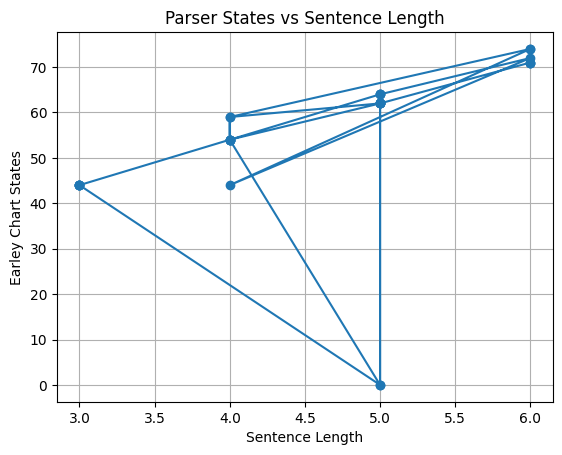


AGREEMENT TESTING
student checks Valid
students submit Valid
students submits Invalid
student submit Invalid
student submits Valid
students check Valid


In [6]:
import nltk
import time
import pandas as pd
import matplotlib.pyplot as plt
from nltk import CFG, PCFG, Nonterminal
from nltk.parse import RecursiveDescentParser, EarleyChartParser, ViterbiParser
g = CFG.fromstring("""
S -> NP VP | VP | AUX NP VP | WH AUX NP VP | WH VP
NP -> DET N | DET ADJ N | DET N PP | PRON | N
VP -> V | V NP | V NP PP | V PP | AUX V
PP -> P NP
DET -> 'the' | 'a' | 'my'
ADJ -> 'late' | 'new'
PRON -> 'i' | 'you' | 'we' | 'they' | 'me'
AUX -> 'can' | 'do' | 'does' | 'is' | 'are' | 'will'
WH -> 'when' | 'where' | 'what' | 'who'
V -> 'show' | 'check' | 'checks' | 'submit' | 'submits' | 'book' | 'books' | 'send' | 'tell' | 'need' | 'want' | 'pay' | 'find' | 'view' | 'download' | 'access'
N -> 'student' | 'students' | 'timetable' | 'exam' | 'exams' | 'hostel' | 'fee' | 'fees' | 'form' | 'room' | 'library' | 'notice' | 'receipt' | 'application' | 'results'
P -> 'with' | 'near' | 'for' | 'to' | 'in' | 'on'
""")
rd = RecursiveDescentParser(g)
ep = EarleyChartParser(g)
rules = g.productions()
groups = {}
for r in rules:
    groups.setdefault(r.lhs(), []).append(r)
pr = []
for lhs, rs in groups.items():
    for r in rs:
        pr.append(nltk.ProbabilisticProduction(lhs, r.rhs(), prob=1/len(rs)))
pg = PCFG(Nonterminal('S'), pr)
vp = ViterbiParser(pg)
sentences = [
"the student checks the timetable",
"the students submit the form",
"the student books the room",
"you check the exam",
"we need the hostel",
"they pay the fee",
"i want the receipt",
"the student downloads the application",
"the students view the results",
"the student accesses the library",
"show the timetable",
"submit the form",
"book the room",
"check the notice",
"find the receipt",
"can you check the timetable",
"can we book the room",
"do you need the form",
"does the student submit the form",
"is the hostel fee",
"when can you book the room",
"where can i find the library",
"what do you need",
"who checks the timetable",
"what can you show",
"the student checks the timetable",
"the students book the room",
"show the students with the notice",
"book the room near the library",
"send the receipt to the student"
]
data = []
for s in sentences:
    w = s.split()
    start = time.time()
    try:
        a = len(list(rd.parse(w)))
    except (ValueError, RecursionError):
        a = 0
    t1 = time.time() - start
    start = time.time()
    try:
        chart = ep.chart_parse(w)
        b = len(list(ep.parse(w)))
        states = len(chart.edges())
    except ValueError:
        b, states = 0, 0
    t2 = time.time() - start
    start = time.time()
    try:
        c = len(list(vp.parse(w)))
    except ValueError:
        c = 0
    t3 = time.time() - start
    data.append([s, len(w), a, b, c, states, t1, t2, t3])
df = pd.DataFrame(data, columns=[
    "Sentence", "Length", "Top-Down", "Earley",
    "Viterbi", "States", "TD Time", "Earley Time", "Viterbi Time"
])
display(df)
print("Total Sentences:", len(df))
print("Top-Down Success:", (df["Top-Down"] > 0).sum())
print("Earley Success:", (df["Earley"] > 0).sum())
print("Viterbi Success:", (df["Viterbi"] > 0).sum())
plt.plot(df["Length"], df["States"], marker='o')
plt.xlabel("Sentence Length")
plt.ylabel("Earley Chart States")
plt.title("Parser States vs Sentence Length")
plt.grid()
plt.show()
tests = [
("student", "checks"),
("students", "submit"),
("students", "submits"),
("student", "submit"),
("student", "submits"),
("students", "check")
]
print("\nAGREEMENT TESTING")
for subject, verb in tests:
    valid = verb in {
        "student": ["checks", "submits"],
        "students": ["check", "submit"]
    }[subject]
    print(subject, verb, "Valid" if valid else "Invalid")


TASK 11

In [10]:
import pandas as pd
comparison = pd.DataFrame({
    "Parameter": [
        "Successful Parses",
        "Average Execution Time",
        "Ambiguity Handling",
        "Total Chart States",
        "Grammar Maintenance"
    ],
    "Top-Down": [
        (df["Top-Down"] > 0).sum(),
        df["TD Time"].mean(),
        "Limited",
        "Not Available",
        "Simple"
    ],
    "Earley": [
        (df["Earley"] > 0).sum(),
        df["Earley Time"].mean(),
        "Multiple Parses",
        df["States"].sum(),
        "Flexible"
    ],
    "Viterbi": [
        (df["Viterbi"] > 0).sum(),
        df["Viterbi Time"].mean(),
        "Best Parse",
        "Not Available",
        "Requires Probabilities"
    ]
})

print("PARSER COMPARISON")
display(comparison)

PARSER COMPARISON


,Parameter,Top-Down,Earley,Viterbi
0,Successful Parses,27,27,27
1,Average Execution Time,0.026252,0.005473,0.004453
2,Ambiguity Handling,Limited,Multiple Parses,Best Parse
3,Total Chart States,Not Available,1649,Not Available
4,Grammar Maintenance,Simple,Flexible,Requires Probabilities


TASK 12

In [16]:
import nltk
import pandas as pd
from nltk import CFG
from nltk.parse import EarleyChartParser
extra = """
S -> S CONJ S | AUX NP VP | NP VP
NP -> DET N REL
REL -> 'that' AUX V
VP -> V PRON WH NP AUX AUX V | AUX ADJ
CONJ -> 'and'
WH -> 'whether'
AUX -> 'were' | 'be'
V -> 'postponed' | 'held' | 'tell'
ADJ -> 'due'
N -> 'fee' | 'exams'
"""
new_grammar = CFG.fromstring(grammar_text + extra)
old_parser = EarleyChartParser(grammar10)
new_parser = EarleyChartParser(new_grammar)
messages = [
"the student checks the timetable",
"the students book the room",
"can you tell me whether the hostel fee is due"
]
results = []
for s in messages:
    words = s.split()
    try:
        old = list(old_parser.parse(words))
        old_result = "Accepted" if old else "Rejected"
    except ValueError:
        old_result = "Rejected"
        old = []
    try:
        new = list(new_parser.parse(words))
        new_result = "Accepted" if new else "Rejected"
    except ValueError:
        new_result = "Rejected"
        new = []
    results.append([
        s, old_result, new_result, len(old), len(new)
    ])

df12 = pd.DataFrame(results, columns=[
    "Message", "Original Grammar",
    "Modified Grammar", "Old Parses", "New Parses"
])
display(df12)
print("Original Coverage:",
      (df12["Original Grammar"] == "Accepted").sum())

print("Modified Coverage:",
      (df12["Modified Grammar"] == "Accepted").sum())

,Message,Original Grammar,Modified Grammar,Old Parses,New Parses
0,the student checks the timetable,Accepted,Accepted,1,1
1,the students book the room,Accepted,Accepted,1,1
2,can you tell me whether the hostel fee is due,Rejected,Rejected,0,0


Original Coverage: 2
Modified Coverage: 2
